In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint
from sympy import *

In [7]:
m1,m2,l,g = symbols('m1 m2 l g')
F = symbols('F')
z1, z2, z3, z4 = symbols('z1 z2 z3 z4')

In [8]:
m1

m1

In [9]:
dz2, dz4 = symbols('dz2 dz4')

In [10]:
dz2

dz2

In [11]:
e1 = (m1 + m2) * dz2 - m2 * l * dz4 * cos(z4) + m2 * l * (z4**2) * sin(z3) - F

In [12]:
e1

-F + dz2*(m1 + m2) - dz4*l*m2*cos(z4) + l*m2*z4**2*sin(z3)

In [13]:
e2 = l * dz4 - dz2 * cos(z3) - g * sin(z3)

In [14]:
e2

-dz2*cos(z3) + dz4*l - g*sin(z3)

In [15]:
result = solve([e1, e2],dz2,dz4, dict = True)
# specify the equations as a list; unknown after this, dz2 and dz4. dict = True, means results come as dictionary

In [16]:
result

[{dz2: F/(m1 - m2*cos(z3)*cos(z4) + m2) + g*m2*sin(z3)*cos(z4)/(m1 - m2*cos(z3)*cos(z4) + m2) - l*m2*z4**2*sin(z3)/(m1 - m2*cos(z3)*cos(z4) + m2),
  dz4: F*cos(z3)/(l*m1 - l*m2*cos(z3)*cos(z4) + l*m2) + g*m1*sin(z3)/(l*m1 - l*m2*cos(z3)*cos(z4) + l*m2) + g*m2*sin(z3)/(l*m1 - l*m2*cos(z3)*cos(z4) + l*m2) - l*m2*z4**2*sin(z3)*cos(z3)/(l*m1 - l*m2*cos(z3)*cos(z4) + l*m2)}]

In [17]:
result[0]

{dz2: F/(m1 - m2*cos(z3)*cos(z4) + m2) + g*m2*sin(z3)*cos(z4)/(m1 - m2*cos(z3)*cos(z4) + m2) - l*m2*z4**2*sin(z3)/(m1 - m2*cos(z3)*cos(z4) + m2),
 dz4: F*cos(z3)/(l*m1 - l*m2*cos(z3)*cos(z4) + l*m2) + g*m1*sin(z3)/(l*m1 - l*m2*cos(z3)*cos(z4) + l*m2) + g*m2*sin(z3)/(l*m1 - l*m2*cos(z3)*cos(z4) + l*m2) - l*m2*z4**2*sin(z3)*cos(z3)/(l*m1 - l*m2*cos(z3)*cos(z4) + l*m2)}

In [18]:
result[0][dz2]

F/(m1 - m2*cos(z3)*cos(z4) + m2) + g*m2*sin(z3)*cos(z4)/(m1 - m2*cos(z3)*cos(z4) + m2) - l*m2*z4**2*sin(z3)/(m1 - m2*cos(z3)*cos(z4) + m2)

In [19]:
result[0][dz4]

F*cos(z3)/(l*m1 - l*m2*cos(z3)*cos(z4) + l*m2) + g*m1*sin(z3)/(l*m1 - l*m2*cos(z3)*cos(z4) + l*m2) + g*m2*sin(z3)/(l*m1 - l*m2*cos(z3)*cos(z4) + l*m2) - l*m2*z4**2*sin(z3)*cos(z3)/(l*m1 - l*m2*cos(z3)*cos(z4) + l*m2)

In [20]:
# simplify these expressions

In [23]:
dz2Solved = simplify(result[0][dz2])
dz4Solved = simplify(result[0][dz4])

In [24]:
dz2Solved

(F + g*m2*sin(z3)*cos(z4) - l*m2*z4**2*sin(z3))/(m1 - m2*cos(z3)*cos(z4) + m2)

In [25]:
dz4Solved

(F*cos(z3) + g*m1*sin(z3) + g*m2*sin(z3) - l*m2*z4**2*sin(2*z3)/2)/(l*(m1 - m2*cos(z3)*cos(z4) + m2))

In [26]:
# give values and lambdify it to a python function

lV = 1
gV = 9.81
m1V = 10
m2V = 1

In [28]:
dz2Solved = dz2Solved.subs(l,lV).subs(g,gV).subs(m1,m1V).subs(m2,m2V)
dz4Solved = dz4Solved.subs(l,lV).subs(g,gV).subs(m1,m1V).subs(m2,m2V)

In [30]:
functionDz2 = lambdify([z1, z2, z3, z4, F],dz2Solved)
functionDz4 = lambdify([z1, z2, z3, z4, F],dz4Solved)

In [41]:
# define the state space
def stateSpaceModel(z, t, timePoints, forceArray):

    forceApplied = np.interp(t, timePoints, forceArray)

    dz2Value = functionDz2(z[0], z[1], z[2], z[3], forceApplied)
    dz4Value = functionDz4(z[0], z[1], z[2], z[3], forceApplied)

    dzdt = [z[1], dz2Value, z[3], dz4Value]
    return dzdt

In [54]:
startTime = 0
endTime = 25

timeSteps = 5000

simulationTime = np.linspace(startTime, endTime, timeSteps)

#forceInput = np.sin(simulationTime) + np.cos(2*simulationTime)

forceInput = np.zeros(shape=(simulationTime.shape))


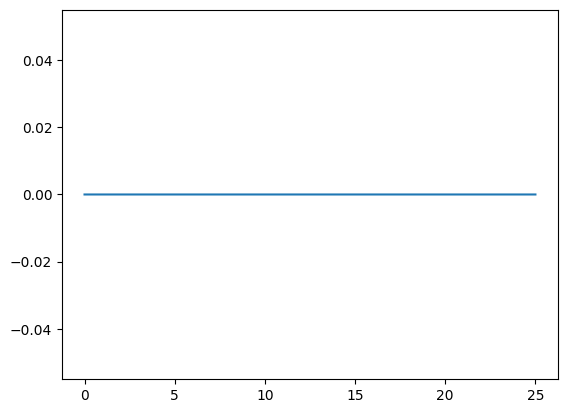

In [55]:
plt.plot(simulationTime, forceInput)

In [56]:
initialState = np.array([0, 0, np.pi/3, 0])

In [57]:
solutionState = odeint(stateSpaceModel, initialState, simulationTime, args=(simulationTime, forceInput))

In [58]:
solutionState

array([[ 0.00000000e+00,  0.00000000e+00,  1.04719755e+00,
         0.00000000e+00],
       [ 1.01159104e-05,  4.04477279e-03,  1.04730885e+00,
         4.45102171e-02],
       [ 4.04398405e-05,  8.07997729e-03,  1.04764274e+00,
         8.90203242e-02],
       ...,
       [-2.29868865e-02, -3.77131017e-01,  2.14623029e+00,
         4.58287899e+00],
       [-2.48941653e-02, -3.85601693e-01,  2.16926337e+00,
         4.62841822e+00],
       [-2.68434094e-02, -3.93912861e-01,  2.19252278e+00,
         4.67338827e+00]])

In [59]:
solutionState.shape # first column z1, then z2, z3, z4

(5000, 4)

### PLOTTING

In [60]:
# save simulation data
# the save file is opened by another Python script that is used
# to animate the trajectory
np.save('simulationData.npy', solutionState)

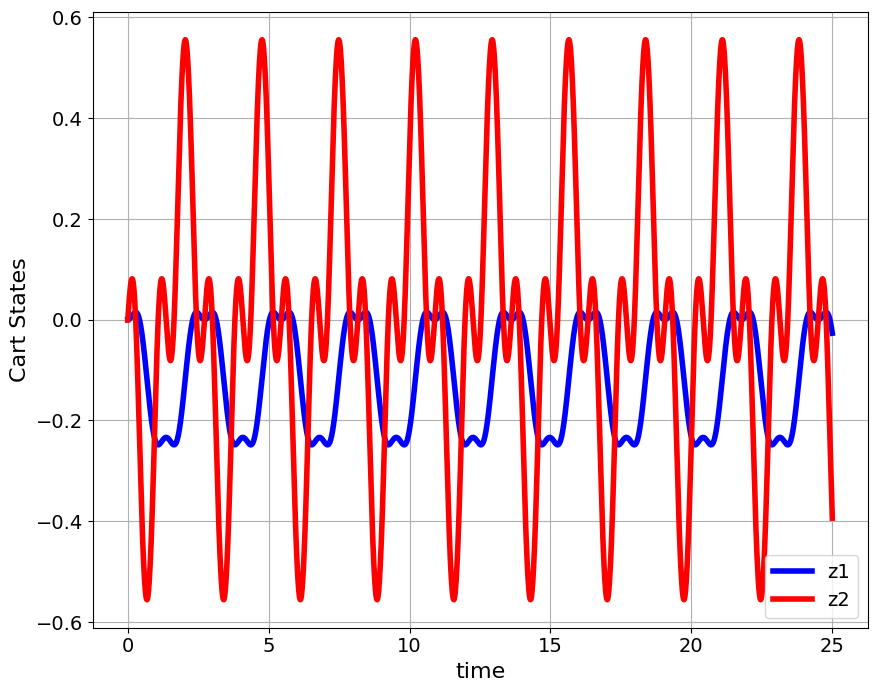

In [61]:
# plot the state trajectories
# cart state trajectories
plt.figure(figsize=(10, 8))
plt.plot(simulationTime, solutionState[:,0], 'b', linewidth = 4, label='z1')
plt.plot(simulationTime, solutionState[:,1], 'r', linewidth = 4, label='z2')
plt.xlabel('time', fontsize=16)
plt.ylabel('Cart States', fontsize=16)
plt.legend(fontsize=14)
plt.tick_params(axis='both', which='major', labelsize=14)
plt.grid()
plt.savefig('cartStates.png', dpi=600)
plt.show()

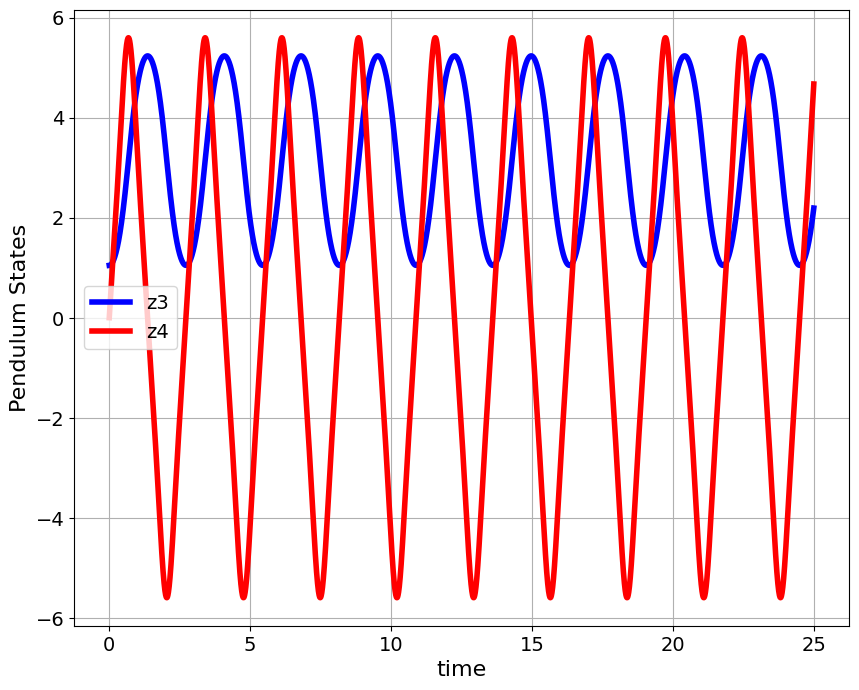

In [62]:
# plot the state trajectories
# pendulum state trajectories
plt.figure(figsize=(10, 8))
plt.plot(simulationTime, solutionState[:,2], 'b', linewidth = 4, label='z3')
plt.plot(simulationTime, solutionState[:,3], 'r', linewidth = 4, label='z4')
plt.xlabel('time', fontsize=16)
plt.ylabel('Pendulum States', fontsize=16)
plt.legend(fontsize=14)
plt.tick_params(axis='both', which='major', labelsize=14)
plt.grid()
plt.savefig('pendulumStates.png', dpi=600)
plt.show()